# Análise de Categorias de Conteúdo por Repositório (Escala Completa)

Este notebook analisa o `regex_analysis_content_ai_context_files.csv`, gerado por `scripts/regex_analysis_content.py`
a partir dos arquivos de contexto de IA baixados por `scripts/download_ai_context_files.py`.

Diferente de `4-structure_analysis_study.ipynb` e `5-ai-file-classification-study.ipynb` (que analisam dados em
formato longo, um *heading* por linha, cobrindo 266 repositórios do snapshot Top 1000/23-03-2026), aqui os dados
estão em formato largo (uma linha por repositório, booleano por categoria) e cobrem **1.238 repositórios** do
snapshot completo Top 10.000/24-08-2025 — todos os repositórios que possuem ao menos 1 arquivo de contexto de IA.

Objetivo: gerar um primeiro diagnóstico quantitativo de conteúdo em escala total, complementando a análise
semântica via LLM já em andamento na RQ01.

## Configurações

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 6]

## Carregamento dos dados

In [2]:
DATA_PATH = "../data/oldData/rq01/regex_analysis_content_ai_context_files.csv"

df = pd.read_csv(DATA_PATH)
print(f"Total de repositórios: {len(df)}")

CATEGORY_COLS = [c for c in df.columns if c not in ['repo', 'categorias_encontradas']]
print(f"Categorias monitoradas: {len(CATEGORY_COLS)}")

df.head()

Total de repositórios: 1238
Categorias monitoradas: 13


,repo,Testing Strategy / Guidelines,Testing Instructions,Architecture / Project Structure,Code Conventions / Best Practices,Contribution Guidelines,Getting Started / Setup,Run / Build Commands,Project Description,Troubleshooting,Security,Doc Metadata / Front-matter,Reference & Examples,Other,categorias_encontradas
0,https://github.com/1technophile/openmqttgateway,False,True,True,True,True,True,True,True,False,False,False,True,True,Testing Instructions; Architecture / Project S...
1,https://github.com/ACINQ/eclair,False,True,True,True,True,True,True,True,False,False,False,False,True,Testing Instructions; Architecture / Project S...
2,https://github.com/AleoNet/snarkOS,False,True,False,True,False,False,False,False,False,False,False,False,True,Testing Instructions; Code Conventions / Best ...
3,https://github.com/Azure/Azure-Sentinel,False,False,True,True,True,False,True,False,False,False,True,True,True,Architecture / Project Structure; Code Convent...
4,https://github.com/Checkmk/checkmk,False,True,False,True,True,False,False,True,False,False,False,False,True,Testing Instructions; Code Conventions / Best ...


## 1. Prevalência de categorias

Em quantos por cento dos 1.238 repositórios cada categoria de conteúdo aparece (em pelo menos um dos arquivos de
contexto de IA do repositório)?

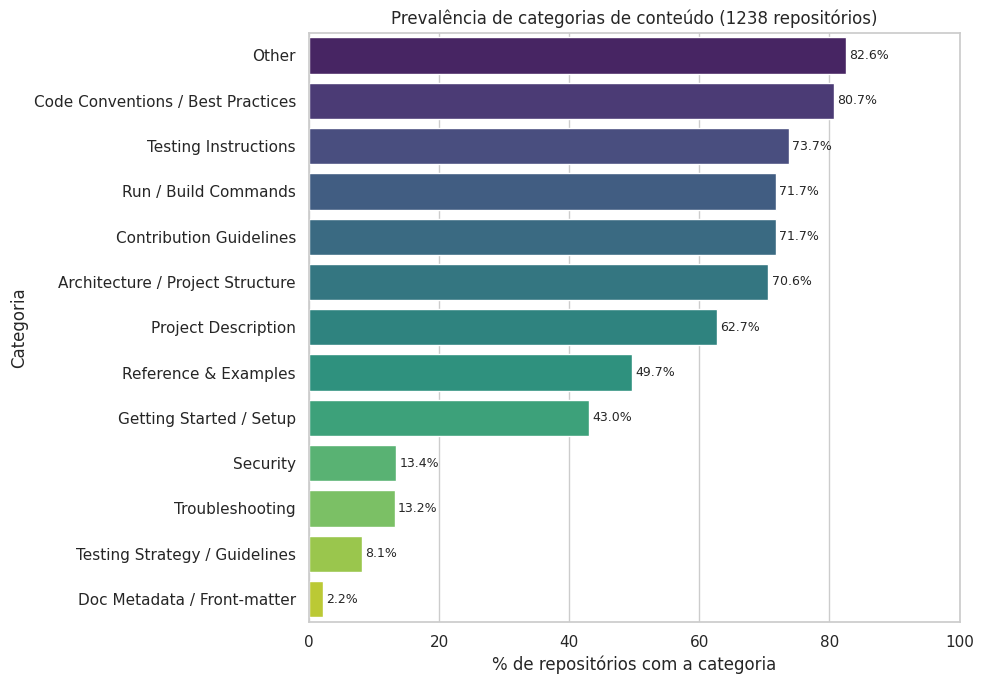

Other                                82.552504
Code Conventions / Best Practices    80.694669
Testing Instructions                 73.747981
Run / Build Commands                 71.728595
Contribution Guidelines              71.728595
Architecture / Project Structure     70.597738
Project Description                  62.681745
Reference & Examples                 49.676898
Getting Started / Setup              42.972536
Security                             13.408724
Troubleshooting                      13.166397
Testing Strategy / Guidelines         8.077544
Doc Metadata / Front-matter           2.180937
dtype: float64

In [3]:
prevalencia = (df[CATEGORY_COLS].mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(10, 7))
ax = sns.barplot(x=prevalencia.values, y=prevalencia.index, hue=prevalencia.index, palette="viridis", legend=False)
plt.title(f"Prevalência de categorias de conteúdo ({len(df)} repositórios)")
plt.xlabel("% de repositórios com a categoria")
plt.ylabel("Categoria")
for i, val in enumerate(prevalencia.values):
    plt.text(val + 0.5, i, f'{val:.1f}%', va='center', fontsize=9)
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

prevalencia

## 2. Amplitude de categorias vs. número de arquivos de contexto

Teste quantitativo (sem depender de LLM) da hipótese H1 da RQ01: repositórios com **mais arquivos de contexto**
cobrem, em média, **mais categorias distintas** (indício de especialização) ou ficam restritos às mesmas poucas
categorias (indício de redundância)?

A categoria `Other` é excluída do cálculo de amplitude por ser um bucket residual, não um tópico de conteúdo real.

In [ ]:
manifest = pd.read_csv("../data/oldData/rq01/rq00/download_manifest.csv")
manifest_ok = manifest[manifest['status'] == 'ok']
qtd_arquivos = manifest_ok.groupby('repo')['file_label'].nunique().rename('qtd_arquivos_contexto')

df['repo_slug'] = df['repo'].str.replace('https://github.com/', '', regex=False)
df = df.merge(qtd_arquivos, left_on='repo_slug', right_index=True, how='left')

sem_correspondencia = df['qtd_arquivos_contexto'].isna().sum()
print(f"Repositórios sem correspondência no manifesto: {sem_correspondencia}")
df['qtd_arquivos_contexto'] = df['qtd_arquivos_contexto'].fillna(1).astype(int)

,count,mean,median,std
qtd_arquivos_contexto,,,,
1,761,5.203679,6.0,2.639136
2,374,6.120321,6.0,2.350966
3,93,6.741935,7.0,2.230730
4,10,6.500000,7.0,3.274480


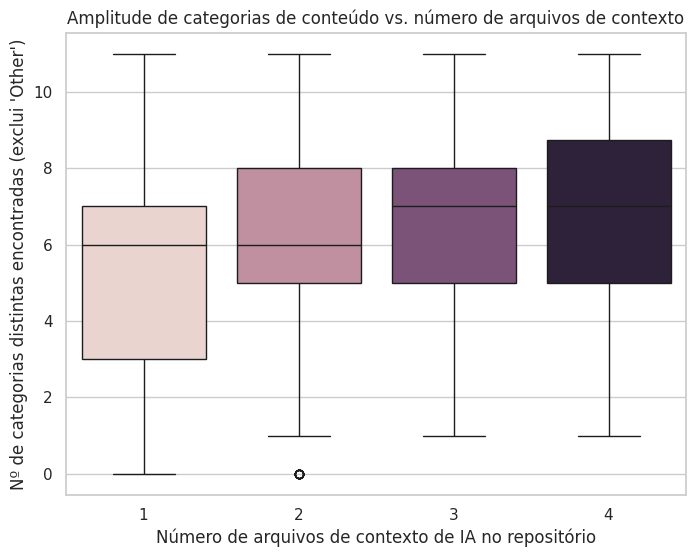

In [5]:
categorias_sem_other = [c for c in CATEGORY_COLS if c != 'Other']
df['qtd_categorias_significativas'] = df[categorias_sem_other].sum(axis=1)

breadth_stats = df.groupby('qtd_arquivos_contexto')['qtd_categorias_significativas'].agg(['count', 'mean', 'median', 'std'])
display(breadth_stats)

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='qtd_arquivos_contexto', y='qtd_categorias_significativas', hue='qtd_arquivos_contexto', legend=False)
plt.title("Amplitude de categorias de conteúdo vs. número de arquivos de contexto")
plt.xlabel("Número de arquivos de contexto de IA no repositório")
plt.ylabel("Nº de categorias distintas encontradas (exclui 'Other')")
plt.show()

### Identificação dos outliers do boxplot acima

Usamos a mesma regra que o `seaborn.boxplot` usa para desenhar pontos soltos: outlier é todo valor fora de
`[Q1 - 1,5×IQR, Q3 + 1,5×IQR]`, calculado **dentro de cada grupo** de `qtd_arquivos_contexto`.

In [6]:
outliers_por_grupo = []

for grupo, sub in df.groupby('qtd_arquivos_contexto'):
    q1 = sub['qtd_categorias_significativas'].quantile(0.25)
    q3 = sub['qtd_categorias_significativas'].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = sub[(sub['qtd_categorias_significativas'] < lower) | (sub['qtd_categorias_significativas'] > upper)].copy()
    outliers['grupo_qtd_arquivos_contexto'] = grupo
    outliers_por_grupo.append(outliers)

df_outliers = pd.concat(outliers_por_grupo)[['repo', 'grupo_qtd_arquivos_contexto', 'qtd_categorias_significativas']]
df_outliers = df_outliers.sort_values(['grupo_qtd_arquivos_contexto', 'qtd_categorias_significativas'])

print(f"Total de outliers encontrados: {len(df_outliers)}")
df_outliers

Total de outliers encontrados: 12


,repo,grupo_qtd_arquivos_contexto,qtd_categorias_significativas
92,https://github.com/astral-sh/uv,2,0
111,https://github.com/azure/azure-container-netwo...,2,0
405,https://github.com/fluentassertions/fluentasse...,2,0
457,https://github.com/go-gitea/gitea,2,0
468,https://github.com/gohugoio/hugo,2,0
571,https://github.com/jazzband/django-oauth-toolkit,2,0
581,https://github.com/jihong88/suneditor,2,0
589,https://github.com/johnbillion/query-monitor,2,0
651,https://github.com/libsdl-org/sdl,2,0
852,https://github.com/openbao/openbao,2,0


**Causa raiz (verificada manualmente em `astral-sh/uv`):** os 12 outliers do grupo de 2 arquivos têm
`qtd_categorias_significativas = 0` porque seus arquivos de contexto não usam headings Markdown (`#`) — por exemplo,
`AGENTS.md` é uma lista de bullets sem heading, e `CLAUDE.md` contém só `@AGENTS.md` (um ponteiro/redirecionamento).
Como `extract_headings_with_levels` só captura o estilo ATX (`# Título`), esses repositórios ficam com zero
headings extraídos — mesmo tendo conteúdo real nas regras. Isso é uma **limitação metodológica do regex**, não um
erro de coleta, e vale registrar como limitação no texto do TCC.

## 3. Co-ocorrência de categorias

Quais categorias tendem a aparecer juntas no mesmo repositório? Correlação (coeficiente phi, via `.corr()` sobre
colunas booleanas 0/1) entre cada par de categorias.

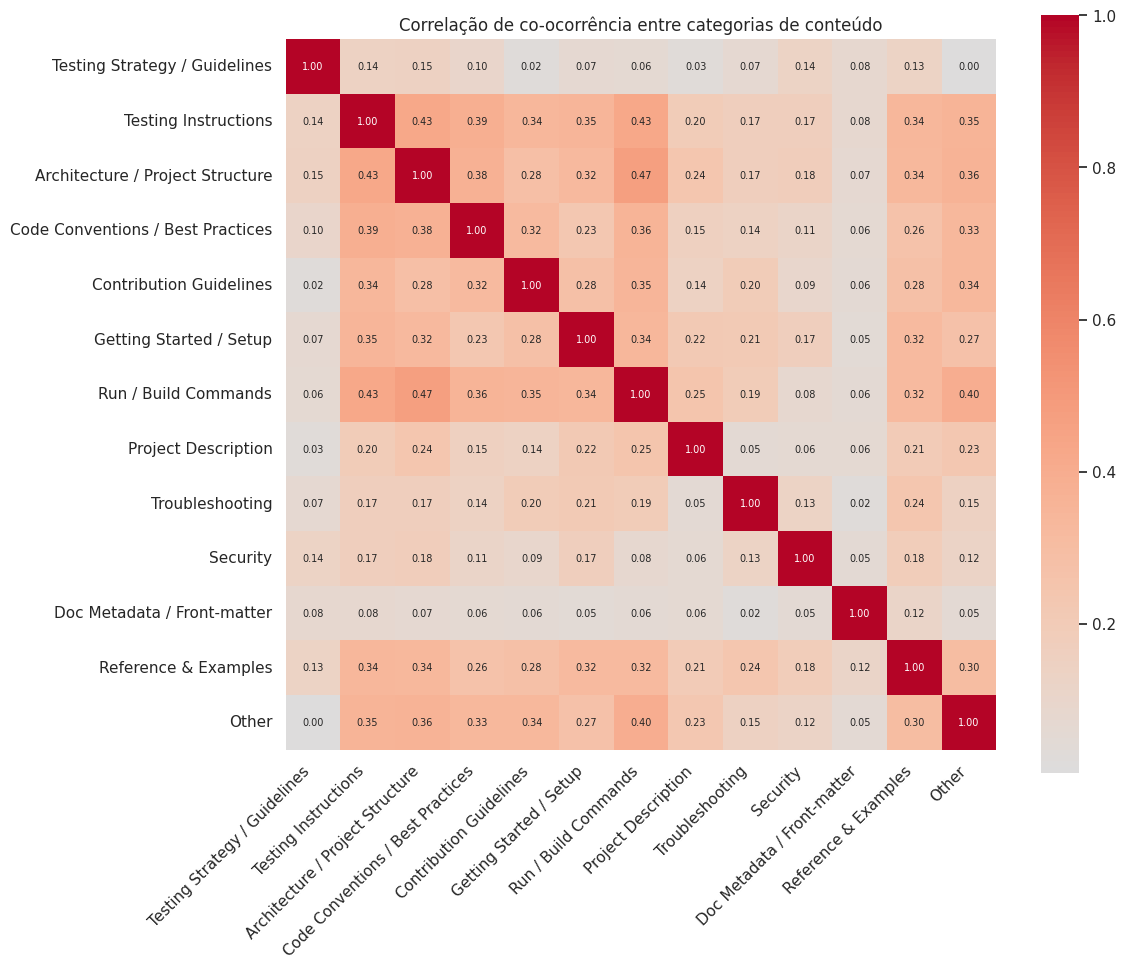

In [7]:
co_occurrence = df[CATEGORY_COLS].astype(int).corr()

plt.figure(figsize=(12, 10))
sns.heatmap(co_occurrence, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, annot_kws={"size": 7})
plt.title("Correlação de co-ocorrência entre categorias de conteúdo")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Observações e limitações

- A classificação de categoria é feita por correspondência de palavras-chave (regex) sobre o título dos
  *headings* — não há validação semântica humana ou via LLM nesta etapa (diferente da análise par-a-par da RQ01).
- A categoria `Other` foi excluída do cálculo de amplitude por ser um bucket residual, não um tópico de conteúdo
  real.
- Esses resultados são quantitativos e em escala completa (1.238 repositórios), complementando — mas não
  substituindo — a validação manual e a análise semântica via LLM já em andamento na RQ01.